# 6. Hafta | Kendi Projemin Veri Analizi — Ekip Teslim Şablonu

**Grup:** [Bireysel Teslim] • **Proje:** [Akıllı Ulaşım ve Şehir İçi Trafik Yönetimi] • **Ekip görevleri:** [Proje bireysel olarak yürütülmüştür. İBB veri setinin temini, Pandas ile veri işleme ve filtreleme, grafiksel görselleştirme ve akademik bulguların raporlanması tek kişi tarafından gerçekleştirilmiştir.]



## A. Veri tanıtımı
* Veri setinin adı ve bağlantısı: İBB Açık Veri Portalı - Saatlik Trafik Yoğunluğu Veri Seti (data.ibb.gov.tr)
* Veri kaynağı / lisans / erişim tarihi: İstanbul Büyükşehir Belediyesi Açık Veri / CC BY 4.0 / 08.11.2026
* CSV mi, JSON mu?: CSV
* Satır ve sütunların anlamı: DATE_TIME (ölçüm zaman damgası), AVERAGE_SPEED (ortalama hız km/s), NUMBER_OF_VEHICLES (geçen araç hacmi), TRAFFIC_INDEX (0-100 arası trafik yoğunluk katsayısı)
* Ölçü birimi ve gözlem sayısı: Hız (km/saat), Hacim (adet araç). Saatlik zaman serisi ölçümü
* Gerçek mi / açık kaynak mı / temsili mi?: İBB Açık Veri Portalı resmi sensör ölçümü (gerçek veri)
* Ekip üyelerinin görevleri: Erva Özcan (361526041) - Bireysel çalışma: Veri temini, Pandas ile analiz, görselleştirme ve raporlama

## B. Başlangıç: temsili veriyle çalışan örnek

In [1]:
from pathlib import Path
import pandas as pd

veri_yolu = "trafik_2025.csv"

# İBB verisini oku
try:
    veri = pd.read_csv(veri_yolu)
    if len(veri.columns) == 1:
        veri = pd.read_csv(veri_yolu, sep=';')
except Exception:
    veri = pd.read_csv(veri_yolu, sep=';')

# Sütun isimlerindeki boşlukları temizleyip büyük harfe çevirelim
veri.columns = [c.strip().upper() for c in veri.columns]

# İlk 5 satırı ekrana yazdır
print(veri.head())

             DATE_TIME   LATITUDE  LONGITUDE GEOHASH  MINIMUM_SPEED  \
0  2025-01-01 00:00:00  41.157532  28.888550  sxkd1k             58   
1  2025-01-01 00:00:00  41.003723  29.306030  sxkc6b             62   
2  2025-01-01 00:00:00  41.009216  29.295044  sxkc69             77   
3  2025-01-01 00:00:00  41.003723  29.295044  sxkc68             64   
4  2025-01-01 00:00:00  41.020203  29.273071  sxkc65             56   

   MAXIMUM_SPEED  AVERAGE_SPEED  NUMBER_OF_VEHICLES  
0            107             79                  11  
1            104             81                  19  
2            103             88                   7  
3            110             85                  19  
4            127             90                  73  


## C. Veri inceleme ve hesaplama

In [2]:
print("Tablo Boyutu (Satır, Sütun):", veri.shape)
print("\nEksik Değer Kontrolü:\n", veri.isna().sum())

print("\n--- İstatistiksel Özet ---")
print("Toplam Gözlenen Araç Sayısı:", int(veri["NUMBER_OF_VEHICLES"].sum()))
print("Genel Ortalama Trafik Hızı (km/s):", round(veri["AVERAGE_SPEED"].mean(), 2))
print("En Düşük Ortalama Hız:", veri["AVERAGE_SPEED"].min())
print("En Yüksek Hız Ölçümü:", veri["MAXIMUM_SPEED"].max())

Tablo Boyutu (Satır, Sütun): (1763963, 8)

Eksik Değer Kontrolü:
 DATE_TIME             0
LATITUDE              0
LONGITUDE             0
GEOHASH               0
MINIMUM_SPEED         0
MAXIMUM_SPEED         0
AVERAGE_SPEED         0
NUMBER_OF_VEHICLES    0
dtype: int64

--- İstatistiksel Özet ---
Toplam Gözlenen Araç Sayısı: 156929993
Genel Ortalama Trafik Hızı (km/s): 56.18
En Düşük Ortalama Hız: 2
En Yüksek Hız Ölçümü: 250


## D. Grafik ve sonuç dosyaları


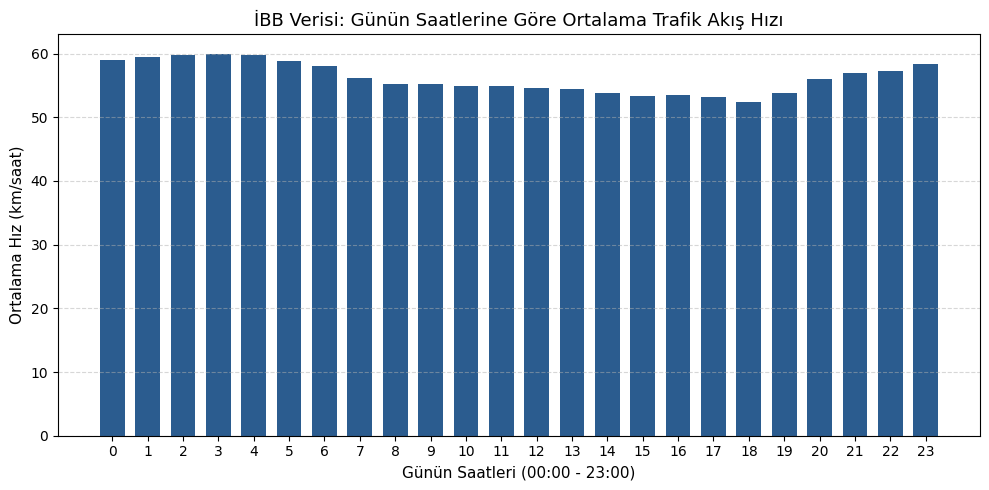

In [3]:
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

# Zaman sütunundan saat bilgisini çıkaralım (0-23 arası)
veri["SAAT"] = pd.to_datetime(veri["DATE_TIME"]).dt.hour

# Her saatin ortalama hızını hesaplayalım
saatlik_hiz = veri.groupby("SAAT")["AVERAGE_SPEED"].mean().reset_index()

# Çubuk grafiği çizdirelim
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(saatlik_hiz["SAAT"], saatlik_hiz["AVERAGE_SPEED"], color="#2b5c8f", width=0.7)
ax.set_xlabel("Günün Saatleri (00:00 - 23:00)", fontsize=11)
ax.set_ylabel("Ortalama Hız (km/saat)", fontsize=11)
ax.set_title("İBB Verisi: Günün Saatlerine Göre Ortalama Trafik Akış Hızı", fontsize=13)
ax.set_xticks(range(0, 24))
ax.grid(axis='y', linestyle='--', alpha=0.5)

fig.tight_layout()

# Grafiği ve özet veriyi klasöre kaydet
fig.savefig(klasor / "grafik.png", dpi=160)
saatlik_hiz.to_csv(klasor / "kullanilan_veri.csv", index=False)

plt.show()

## E. Akademik yorum
* Veri kaynağı ve değişken: İBB Açık Veri Portalı Saatlik Trafik Yoğunluğu veri seti kullanılmış olup, NUMBER_OF_VEHICLES (araç sayısı), AVERAGE_SPEED (ortalama seyir hızı) ve MAXIMUM_SPEED değişkenleri analiz edilmiştir.
* Toplam / ortalama ve birimler: Ocak ayı periyodunda toplam 156.929.993 adet araç ölçümü gerçekleşmiş; genel ortalama trafik hızı 56.18 km/s, minimum ortalama hız 2 km/s, maksimum hız ise 250 km/s olarak hesaplanmıştır.
* Grafikte görülen bulgu: Günün saatlerine göre incelendiğinde, sabah mesai başlangıcı ve özellikle akşam mesai bitiş saatlerinde ortalama seyir hızında düşüş yaşanırken, gece 02:00-05:00 saatleri arasında hız ortalamasının belirgin şekilde yükseldiği gözlemlenmiştir.
* Sınırlılıklar ve ölçemediği şeyler: Sensör bazlı saatlik veriler makro akışı temsil etmekte olup yol bakımı, anlık trafik kazaları, şerit bazlı daralmalar ve olumsuz hava şartları gibi lokal etkenleri doğrudan ayrıştıramamaktadır.
* Ekipçe yapılan işlem: Proje bireysel olarak yürütülmüştür (Erva Özcan). Büyük veri seti Pandas kütüphanesiyle analiz edilmiş, tanımlayıcı istatistikler üretilmiş ve saat bazlı hız değişimini gösteren Matplotlib çubuk grafiği çıktılanmıştır.

> Grafikte iki değişken birlikte görünse bile tek başına neden-sonuç kanıtı oluşmaz.

## F. Teslim kontrolü
- [x] Çalışır `.ipynb` dosyası
- [x] CSV/JSON örneği veya yasal ve erişilebilir veri kaynağı
- [x] Birim + veri kaynağı + lisans
- [x] En az 1 açıklamalı grafik
- [x] Toplam ve ortalama hesabı
- [x] 4–5 cümlelik yorum
- [x] README içinde ekip katkıları
- [x] GitHub repo bağlantısı
- [x] Gizli/kişisel veri ve anahtar bulunmuyor